In [1]:
!pip install mtcnn
!pip install lz4
!pip install -q transformers
!pip install tensorflow-addons

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 611.8/611.8 kB 14.4 MB/s eta 0:00:00
  Attempting uninstall: typeguard
    Found existing installation: typeguard 4.4.1
    Uninstalling typeguard-4.4.1:
      Successfully uninstalled typeguard-4.4.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
inflect 7.4.0 requires typeguard>=4.0.1, but you have typeguard 2.13.3 which is incompatible.
ydata-profiling 4.12.2 requires typeguard<5,>=3, but you have typeguard 2.13.3 which is incompatible.


In [2]:
import os
import shutil
import cv2
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Apply CLAHE to improve contrast
def preprocess_image(image_path, target_size=(224, 224)):
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    image = cv2.resize(image, target_size)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(image)

# Preprocess and save images to a new directory
def preprocess_dataset(input_dir, output_dir, target_size=(224, 224)):
    os.makedirs(output_dir, exist_ok=True)
    for emotion in os.listdir(input_dir):
        emotion_dir = os.path.join(input_dir, emotion)
        output_emotion_dir = os.path.join(output_dir, emotion)
        os.makedirs(output_emotion_dir, exist_ok=True)

        for img_name in os.listdir(emotion_dir):
            img_path = os.path.join(emotion_dir, img_name)
            processed_img = preprocess_image(img_path, target_size=target_size)
            output_path = os.path.join(output_emotion_dir, img_name)
            cv2.imwrite(output_path, processed_img)

# Preprocess combined training and testing datasets
preprocessed_train = '/kaggle/working/preprocessed/train'
preprocessed_test = '/kaggle/working/preprocessed/test'

combined_train = '/kaggle/input/combined/combined/train'
combined_test = '/kaggle/input/combined/combined/test'

preprocess_dataset(combined_train, preprocessed_train)
preprocess_dataset(combined_test, preprocessed_test)
print("Preprocessing completed!")

Preprocessing completed!



Class Distribution (Before Balancing):
 Class 'sad': 6811 images
 Class 'happy': 11986 images
 Class 'fear': 4378 images
 Class 'surprise': 4460 images
 Class 'angry': 4693 images
 Class 'disgust': 1153 images
 Class 'neutral': 7488 images
Largest class count (pre-balancing): 11986
Class fear has 4378 images; oversampling ratio: 2
Class surprise has 4460 images; oversampling ratio: 2
Class angry has 4693 images; oversampling ratio: 2
Class disgust has 1153 images; oversampling ratio: 10

Class Distribution (After Balancing):
 Class 'sad': 6811 images
 Class 'happy': 11986 images
 Class 'fear': 7886 images
 Class 'surprise': 8033 images
 Class 'angry': 8493 images
 Class 'disgust': 7626 images
 Class 'neutral': 7488 images
Found 58323 images belonging to 7 classes.
Class distribution in generator: {0: 8493, 1: 7626, 2: 7886, 3: 11986, 4: 7488, 5: 6811, 6: 8033}

Computed Class Weights (After Balancing):
{0: 0.9810263914820608, 1: 1.092559289648196, 2: 1.05653780660121, 3: 0.69513241639

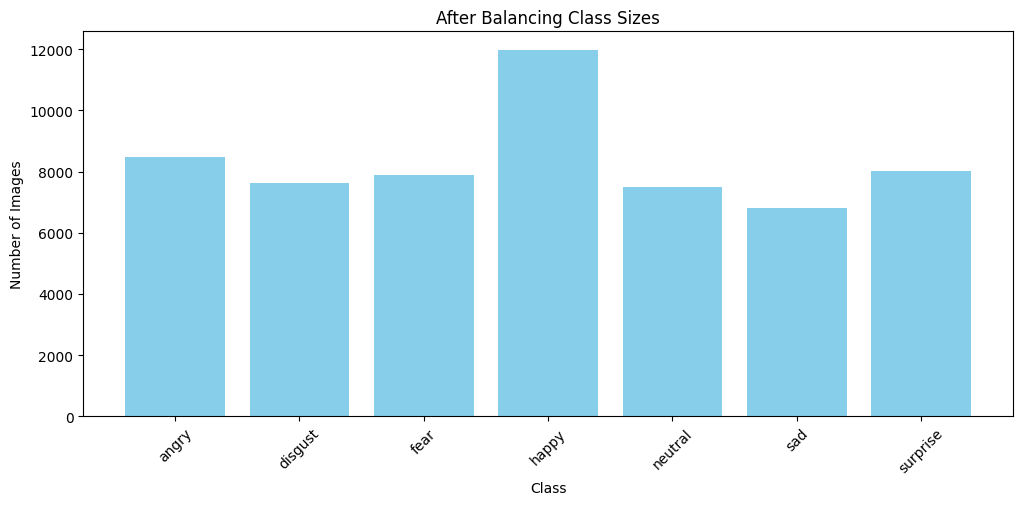

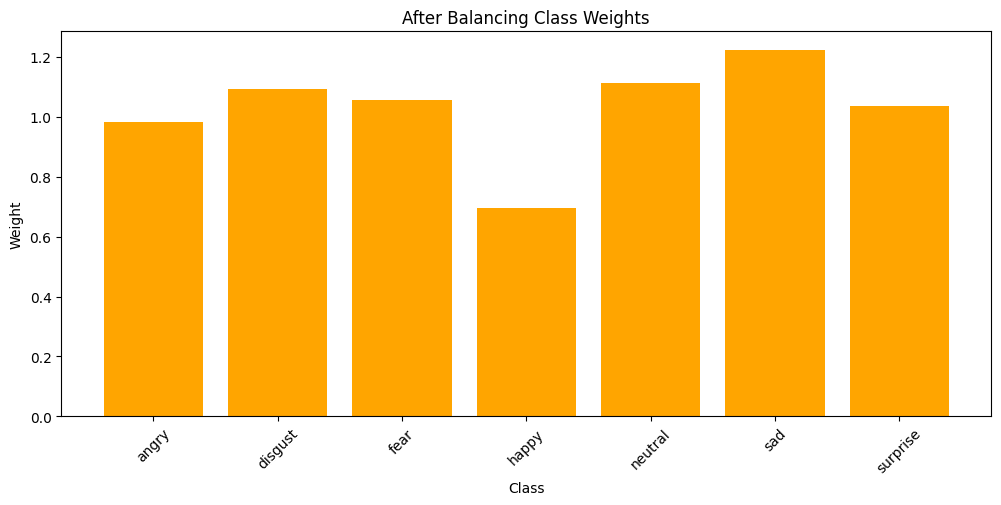

In [3]:
import os
import shutil
import cv2
import numpy as np
import math
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight

# ==============================
#   1) Helper Functions
# ==============================

def get_class_distribution(directory):
    """
    Dynamically discover how many images each class folder contains.
    Returns a dict: { 'class_folder_name': count_of_images, ... }
    """
    distribution = {}
    if not os.path.exists(directory):
        print(f"Directory does not exist: {directory}")
        return distribution

    classes = [d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))]
    for class_name in classes:
        class_dir = os.path.join(directory, class_name)
        distribution[class_name] = len(os.listdir(class_dir))
    return distribution

def oversample_based_on_distribution(
    input_dir,
    output_dir,
    class_distribution,
    target_size=(224, 224),
    fill_mode='nearest'
):
    """
    Dynamically oversample classes to match the size of the largest class.
    
    Args:
        input_dir (str): Directory of the preprocessed dataset (by class folders).
        output_dir (str): Where to save the oversampled dataset.
        class_distribution (dict): e.g. {'0': 4693, '1': 1153, '2': 4378, '3': 11986, ...}
        target_size (tuple): Image size (height, width).
        fill_mode (str): Fill mode for augmentation.
    """
    datagen = ImageDataGenerator(
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True,
        zoom_range=0.1,
        fill_mode=fill_mode
    )
    os.makedirs(output_dir, exist_ok=True)

    # 1. Find the largest class
    max_count = max(class_distribution.values()) if class_distribution else 0
    print(f"Largest class count (pre-balancing): {max_count}")

    # 2. For each class, compute how many times to replicate
    for class_name, file_count in class_distribution.items():
        input_class_dir = os.path.join(input_dir, class_name)
        output_class_dir = os.path.join(output_dir, class_name)
        os.makedirs(output_class_dir, exist_ok=True)

        files = os.listdir(input_class_dir)
        
        # Always copy the original images
        for f in files:
            shutil.copy(os.path.join(input_class_dir, f), output_class_dir)

        # If class has no images, skip
        if file_count == 0:
            print(f"Skipping class '{class_name}' - no images.")
            continue

        # ratio = how many times bigger the largest class is, compared to the current class
        ratio = max_count // file_count
        if ratio <= 1:
            # This class is already near or at the largest
            continue
        
        print(f"Class {class_name} has {file_count} images; oversampling ratio: {ratio}")

        # Generate 'ratio - 1' (or 'ratio') new images per original
        oversample_factor = ratio - 1  # Adjust if you want more/less

        for f in files:
            img_path = os.path.join(input_class_dir, f)
            img = cv2.imread(img_path)
            if img is None:
                continue

            img = cv2.resize(img, target_size)
            img = img.astype('float32') / 255.0
            img = img.reshape((1,) + img.shape)

            i = 0
            for batch in datagen.flow(
                img, 
                batch_size=1,
                save_to_dir=output_class_dir,
                save_prefix=f"aug_{class_name}", 
                save_format='jpeg'
            ):
                i += 1
                if i >= oversample_factor:
                    break

def compute_dynamic_class_weights(generator):
    """
    Computes class weights dynamically based on the class distribution in the dataset.
    Args:
        generator (DirectoryIterator): The generator to compute class weights from.
    Returns:
        dict: Dictionary of class weights { class_index: weight, ... }
    """
    class_counts = Counter(generator.classes)
    print("Class distribution in generator:", dict(class_counts))

    classes = np.unique(generator.classes)
    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=generator.classes
    )
    return dict(enumerate(class_weights))

def visualize_class_distribution_and_weights(generator, class_weights_dict, title_prefix=""):
    """
    Visualizes the class distribution and weights as plots and a table.
    Args:
        generator: The data generator used to compute class distribution.
        class_weights_dict: Dictionary of class weights.
        title_prefix: String to prepend to plot titles (e.g. "Before Balancing" / "After Balancing").
    """
    class_indices = generator.class_indices
    # Sort class names by index
    sorted_class_names = sorted(class_indices, key=class_indices.get)

    # Count the number of samples per class
    class_counts = Counter(generator.classes)

    # Build arrays for plot
    class_sizes = []
    weights = []
    for cname in sorted_class_names:
        idx = class_indices[cname]
        class_sizes.append(class_counts[idx])
        weights.append(class_weights_dict.get(idx, 1.0))

    df = pd.DataFrame({
        "Class Name": sorted_class_names,
        "Number of Images": class_sizes,
        "Class Weight": weights
    })

    # Display the table
    print(f"\n{title_prefix} Class Distribution and Weights:")
    print(df)

    # Plot the class sizes
    plt.figure(figsize=(12, 5))
    plt.bar(sorted_class_names, class_sizes, color='skyblue')
    plt.title(f"{title_prefix} Class Sizes")
    plt.xlabel("Class")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45)
    plt.show()

    # Plot the class weights
    plt.figure(figsize=(12, 5))
    plt.bar(sorted_class_names, weights, color='orange')
    plt.title(f"{title_prefix} Class Weights")
    plt.xlabel("Class")
    plt.ylabel("Weight")
    plt.xticks(rotation=45)
    plt.show()


# Paths
oversampled_train = '/kaggle/working/oversampled/train'
preprocessed_train = '/kaggle/working/preprocessed/train'

# 1. Compute & Print Distribution BEFORE Balancing
pre_balancing_dist = get_class_distribution(preprocessed_train)
print("\nClass Distribution (Before Balancing):")
for k, v in pre_balancing_dist.items():
    print(f" Class '{k}': {v} images")

# 2. Oversample
oversample_based_on_distribution(
    input_dir=preprocessed_train,
    output_dir=oversampled_train,
    class_distribution=pre_balancing_dist,  # Computed distribution
    target_size=(224, 224),
    fill_mode='nearest'
)

# 3. Compute & Print Distribution AFTER Balancing
post_balancing_dist = get_class_distribution(oversampled_train)
print("\nClass Distribution (After Balancing):")
for k, v in post_balancing_dist.items():
    print(f" Class '{k}': {v} images")

# 4. Create Generators & Compute Weights
img_size = (224, 224)
batch_size = 16

train_datagen = ImageDataGenerator(rescale=1.0/255.0)
oversampled_generator = train_datagen.flow_from_directory(
    oversampled_train,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=True
)

class_weights_dict = compute_dynamic_class_weights(oversampled_generator)
print("\nComputed Class Weights (After Balancing):")
print(class_weights_dict)

# 5. Visualize final distribution & weights
visualize_class_distribution_and_weights(oversampled_generator, class_weights_dict, title_prefix="After Balancing")


In [4]:
oversampled_test = '/kaggle/working/oversampled/test'
preprocessed_test = '/kaggle/working/preprocessed/test'

# 1. Compute & Print Distribution BEFORE Balancing
pre_balancing_dist = get_class_distribution(preprocessed_test)
print("\nClass Distribution (Before Balancing):")
for k, v in pre_balancing_dist.items():
    print(f" Class '{k}': {v} images")

# 2. Oversample
oversample_based_on_distribution(
    input_dir=preprocessed_test,
    output_dir=oversampled_test,
    class_distribution=pre_balancing_dist,  # Computed distribution
    target_size=(224, 224),
    fill_mode='nearest'
)

# 3. Compute & Print Distribution AFTER Balancing
post_balancing_dist = get_class_distribution(oversampled_test)
print("\nClass Distribution (After Balancing):")
for k, v in post_balancing_dist.items():
    print(f" Class '{k}': {v} images")



Class Distribution (Before Balancing):
 Class 'sad': 1725 images
 Class 'happy': 2959 images
 Class 'fear': 1098 images
 Class 'surprise': 1160 images
 Class 'angry': 1119 images
 Class 'disgust': 271 images
 Class 'neutral': 1913 images
Largest class count (pre-balancing): 2959
Class fear has 1098 images; oversampling ratio: 2
Class surprise has 1160 images; oversampling ratio: 2
Class angry has 1119 images; oversampling ratio: 2
Class disgust has 271 images; oversampling ratio: 10

Class Distribution (After Balancing):
 Class 'sad': 1725 images
 Class 'happy': 2959 images
 Class 'fear': 2151 images
 Class 'surprise': 2255 images
 Class 'angry': 2170 images
 Class 'disgust': 2435 images
 Class 'neutral': 1913 images


In [5]:
import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import pandas as pd

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, Dropout,
    BatchNormalization, Conv2D, Multiply,
    Lambda, Concatenate, Reshape, Input
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)
from sklearn.preprocessing import label_binarize

# ---- NEW IMPORTS FOR ViT ----
from transformers import TFViTModel

In [6]:

class ViTWrapper(tf.keras.layers.Layer):
    """
    A custom Keras layer that wraps TFViTModel and ensures compatibility with the functional API.
    """
    def __init__(self, pretrained_name="google/vit-base-patch16-224-in21k", **kwargs):
        super().__init__(**kwargs)
        self.vit_model = TFViTModel.from_pretrained(pretrained_name)

    def call(self, inputs, training=False):
        # Transpose to channels-first for ViT
        x = tf.transpose(inputs, perm=[0, 3, 1, 2])  # (B, 3, 224, 224)
        # Normalize inputs (optional, approximate mean/std)
        x = (x - 0.5) / 0.5
        outputs = self.vit_model(pixel_values=x, training=training)
        return outputs.pooler_output

    def unfreeze_layers(self):
        """Unfreeze all layers in the ViT model."""
        for layer in self.vit_model.layers:
            layer.trainable = True


In [7]:
# -----------------------------
# Squash Activation Function for Capsules
# -----------------------------
def squash(s, axis=-1, epsilon=1e-7):
    s_squared_norm = tf.reduce_sum(tf.square(s), axis=axis, keepdims=True)
    scale = s_squared_norm / (1 + s_squared_norm)
    return scale * s / tf.sqrt(s_squared_norm + epsilon)

# -----------------------------
# Advanced Capsule Fusion Block (CFB)
# -----------------------------
class AdvancedCapsuleFusionBlock(tf.keras.layers.Layer):
    """
    Advanced Capsule Fusion Block that fuses two feature vectors using an iterative dynamic routing
    algorithm with enhanced transformations, residual updates, dropout, and batch normalization.
    """
    def __init__(self, capsule_dim=256, num_iterations=2, dropout_rate=0.4, **kwargs):
        super(AdvancedCapsuleFusionBlock, self).__init__(**kwargs)
        self.capsule_dim = capsule_dim
        self.num_iterations = num_iterations
        self.dropout_rate = dropout_rate
        
        # Two-layer MLP for each branch's transformation
        self.mlp1 = tf.keras.Sequential([
            Dense(capsule_dim, activation="relu"),
            Dropout(dropout_rate),
            Dense(capsule_dim, activation=None)
        ])
        self.bn1 = BatchNormalization()
        
        self.mlp2 = tf.keras.Sequential([
            Dense(capsule_dim, activation="relu"),
            Dropout(dropout_rate),
            Dense(capsule_dim, activation=None)
        ])
        self.bn2 = BatchNormalization()
    
    def call(self, inputs, training=False):
        # inputs: list [f1, f2] from two branches
        f1, f2 = inputs
        # Transform each branch using a two-layer MLP
        u1 = self.bn1(self.mlp1(f1), training=training)  # (batch, capsule_dim)
        u2 = self.bn2(self.mlp2(f2), training=training)  # (batch, capsule_dim)
        
        # Stack to form capsules: shape (batch, 2, capsule_dim)
        u = tf.stack([u1, u2], axis=1)
        
        # Initialize routing logits b (batch, 2) with zeros
        b = tf.zeros(shape=(tf.shape(u)[0], 2), dtype=tf.float32)
        
        # Iterative dynamic routing
        for i in range(self.num_iterations):
            c = tf.nn.softmax(b, axis=1)  # coupling coefficients (batch, 2)
            c_expanded = tf.expand_dims(c, axis=-1)  # (batch, 2, 1)
            # Weighted sum of capsule predictions
            s = tf.reduce_sum(c_expanded * u, axis=1)  # (batch, capsule_dim)
            v = squash(s, axis=-1)  # (batch, capsule_dim)
            
            # Residual update: encourage consistency with previous capsule output
            if i > 0:
                v = 0.5 * v + 0.5 * v_prev
            v_prev = v  # store for residual update
            
            v_expanded = tf.expand_dims(v, axis=1)  # (batch, 1, capsule_dim)
            # Update routing logits based on agreement
            b += tf.reduce_sum(u * v_expanded, axis=-1)  # (batch, 2)
        return v  # Final fused capsule (batch, capsule_dim)


In [8]:
# -----------------------------
# Positional Embedding Layer for TRB
# -----------------------------
class PositionalEmbedding(tf.keras.layers.Layer):
    """
    Learns a positional embedding for a fixed number of tokens.
    """
    def __init__(self, num_tokens, token_dim, **kwargs):
        super(PositionalEmbedding, self).__init__(**kwargs)
        self.num_tokens = num_tokens
        self.token_dim = token_dim

    def build(self, input_shape):
        # Create a learnable positional embedding matrix
        self.pos_embedding = self.add_weight(
            shape=(1, self.num_tokens, self.token_dim),
            initializer="uniform",
            trainable=True,
            name="pos_embedding"
        )
        super(PositionalEmbedding, self).build(input_shape)

    def call(self, inputs):
        # inputs shape: (batch, num_tokens, token_dim)
        return inputs + self.pos_embedding

# -----------------------------
# Advanced Transformer Encoder Block for TRB
# -----------------------------
class TransformerEncoderBlock(tf.keras.layers.Layer):
    """
    A full transformer encoder block with multi-head self-attention, feed-forward network,
    residual connections, and layer normalization.
    """
    def __init__(self, token_dim, num_heads, ff_dim, dropout_rate=0.4, **kwargs):
        super(TransformerEncoderBlock, self).__init__(**kwargs)
        self.mha = tf.keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=token_dim)
        self.ffn = tf.keras.Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(token_dim)
        ])
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(dropout_rate)
        self.dropout2 = Dropout(dropout_rate)
    
    def call(self, inputs, training=False):
        attn_output = self.mha(inputs, inputs, training=training)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

# -----------------------------
# Advanced Transformer Refinement Block (TRB)
# -----------------------------
class AdvancedTransformerRefinementBlock(tf.keras.layers.Layer):
    """
    Refines the fused capsule features using a stack of transformer encoder blocks.
    The fused vector is projected into multiple tokens, positional embeddings are added,
    processed by transformer layers, and then aggregated.
    """
    def __init__(self, num_tokens=4, token_dim=64, num_heads=4, ff_dim=128, num_layers=2, dropout_rate=0.3, **kwargs):
        super(AdvancedTransformerRefinementBlock, self).__init__(**kwargs)
        self.num_tokens = num_tokens
        self.token_dim = token_dim
        self.proj = Dense(num_tokens * token_dim)
        self.reshape_layer = Lambda(lambda x: tf.reshape(x, (-1, num_tokens, token_dim)))
        self.pos_emb = PositionalEmbedding(num_tokens, token_dim)
        self.transformer_layers = [TransformerEncoderBlock(token_dim, num_heads, ff_dim, dropout_rate) for _ in range(num_layers)]
    
    def call(self, inputs, training=False):
        # inputs: fused capsule features (batch, capsule_dim)
        tokens = self.proj(inputs)                # (batch, num_tokens * token_dim)
        tokens = self.reshape_layer(tokens)         # (batch, num_tokens, token_dim)
        tokens = self.pos_emb(tokens)               # Add positional embedding
        for layer in self.transformer_layers:
            tokens = layer(tokens, training=training)
        # Aggregate tokens via mean pooling
        refined = tf.reduce_mean(tokens, axis=1)    # (batch, token_dim)
        return refined

# focal loss

In [9]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import Sequence

class MixupSequence(Sequence):
    def __init__(self, datagen, alpha=0.1):
        """
        Wraps a Keras ImageDataGenerator (Sequence) to perform MixUp on each batch.
        
        Args:
            datagen: A Keras ImageDataGenerator Sequence (e.g., from flow_from_directory).
            alpha: Beta distribution parameter for mixing. Higher alpha means stronger mixing.
        """
        self.datagen = datagen
        self.alpha = alpha
        self.batch_size = datagen.batch_size
        self.steps = len(datagen)

    def __len__(self):
        # Return the number of batches per epoch
        return self.steps

    def __getitem__(self, idx):
        # Get the idx-th batch from the underlying generator
        batch_x, batch_y = self.datagen[idx]
        batch_size = batch_x.shape[0]
        
        # Sample lambda from Beta(alpha, alpha)
        lam = np.random.beta(self.alpha, self.alpha)
        
        # Shuffle batch indices
        index = np.random.permutation(batch_size)
        
        # Perform MixUp on images and labels
        mixed_x = lam * batch_x + (1 - lam) * batch_x[index, :]
        mixed_y = lam * batch_y + (1 - lam) * batch_y[index, :]
        
        return mixed_x, mixed_y


In [10]:
def focal_loss(alpha, gamma=2.0):
    """
    Focal Loss for multi-class classification.
    
    Args:
        alpha: A list or array of weights for each class (class importance).
        gamma: Focusing parameter to reduce the loss contribution from easy examples.
    
    Returns:
        A loss function that can be used in model.compile().
    """
    def loss_fn(y_true, y_pred):
        # Ensure predictions are probabilities
        y_pred = tf.keras.backend.clip(y_pred, 1e-3, 1 - 1e-3)
        
        # Compute the cross-entropy loss
        ce_loss = -y_true * tf.math.log(y_pred)
        
        # Apply the focal loss adjustment
        focal_loss = alpha * tf.pow(1 - y_pred, gamma) * ce_loss
        
        # Return the mean focal loss over the batch
        return tf.reduce_mean(tf.reduce_sum(focal_loss, axis=-1))
    
    return loss_fn


Found 58323 images belonging to 7 classes.
Found 15608 images belonging to 7 classes.
Class distribution in generator: {0: 8493, 1: 7626, 2: 7886, 3: 11986, 4: 7488, 5: 6811, 6: 8033}

Oversampled Train Class Distribution and Weights:
  Class Name  Number of Images  Class Weight
0      angry              8493      0.981026
1    disgust              7626      1.092559
2       fear              7886      1.056538
3      happy             11986      0.695132
4    neutral              7488      1.112695
5        sad              6811      1.223294
6   surprise              8033      1.037204


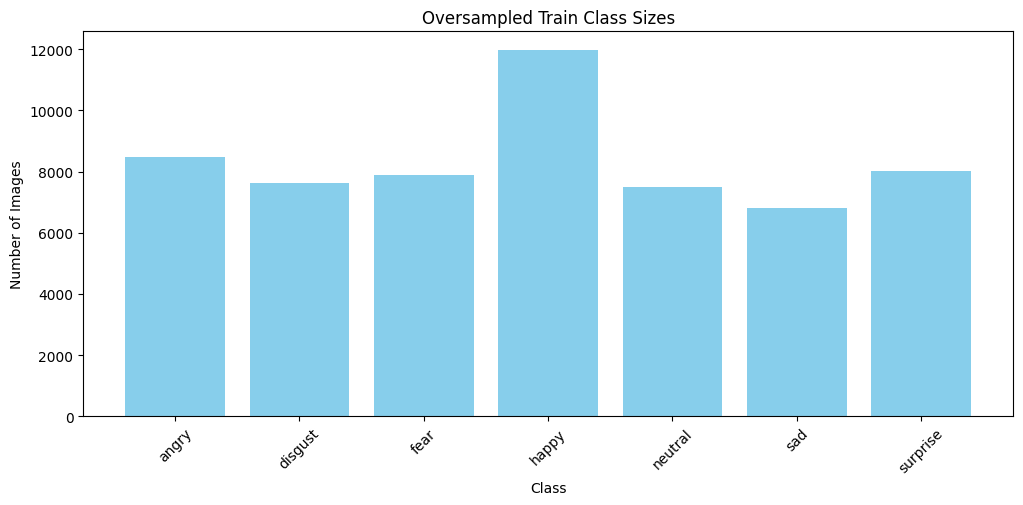

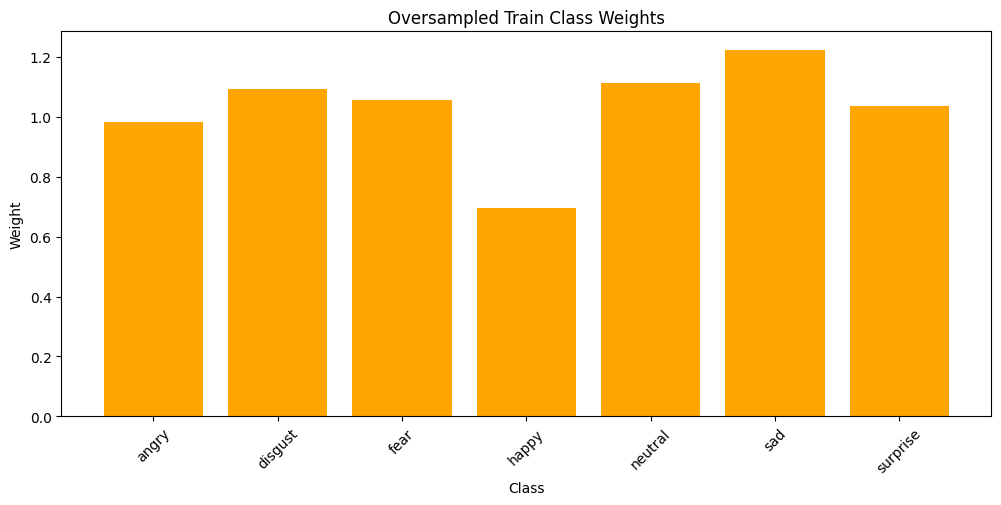

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

All PyTorch model weights were used when initializing TFViTModel.

All the weights of TFViTModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFViTModel for predictions without further training.



=== Phase 1 Training ===
Epoch 1/25


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3646/3646 ━━━━━━━━━━━━━━━━━━━━ 905s 237ms/step - accuracy: 0.3130 - loss: 0.1759 - val_accuracy: 0.5473 - val_loss: 0.1124 - learning_rate: 3.0000e-05
Epoch 2/25
3646/3646 ━━━━━━━━━━━━━━━━━━━━ 839s 230ms/step - accuracy: 0.4968 - loss: 0.1281 - val_accuracy: 0.6201 - val_loss: 0.0856 - learning_rate: 3.0000e-05
Epoch 3/25
3646/3646 ━━━━━━━━━━━━━━━━━━━━ 834s 228ms/step - accuracy: 0.5530 - loss: 0.1113 - val_accuracy: 0.6447 - val_loss: 0.0788 - learning_rate: 3.0000e-05
Epoch 4/25
3646/3646 ━━━━━━━━━━━━━━━━━━━━ 836s 229ms/step - accuracy: 0.5915 - loss: 0.1010 - val_accuracy: 0.6751 - val_loss: 0.0721 - learning_rate: 3.0000e-05
Epoch 5/25
3646/3646 ━━━━━━━━━━━━━━━━━━━━ 828s 227ms/step - accuracy: 0.6242 - loss: 0.0942 - val_accuracy: 0.6476 - val_loss: 0.0832 - learning_rate: 3.0000e-05
Epoch 6/25
3646/3646 ━━━━━━━━━━━━━━━━━━━━ 827s 226ms/step - accuracy: 0.6468 - loss: 0.0888 - val_accuracy: 0.7042 - val_loss: 0.0647 - learning_rate: 3.0000e-05
Epoch 7/25
3646/3646 ━━━━━━━━━━━━━━━━━━

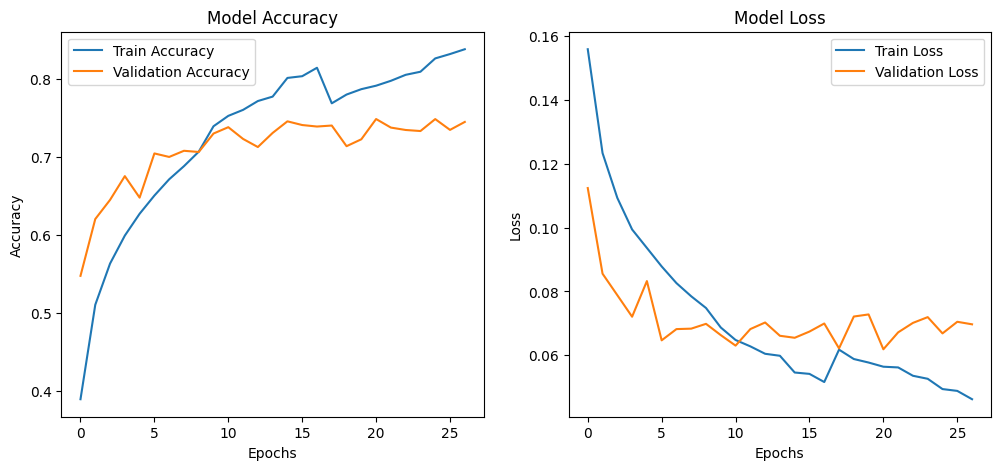

976/976 ━━━━━━━━━━━━━━━━━━━━ 127s 125ms/step

Classification Report:
              precision    recall  f1-score   support

       angry       0.70      0.62      0.65      2170
     disgust       0.85      0.85      0.85      2435
        fear       0.64      0.56      0.60      2151
       happy       0.89      0.89      0.89      2959
     neutral       0.64      0.74      0.69      1913
         sad       0.59      0.64      0.62      1725
    surprise       0.82      0.84      0.83      2255

    accuracy                           0.75     15608
   macro avg       0.73      0.74      0.73     15608
weighted avg       0.75      0.75      0.75     15608



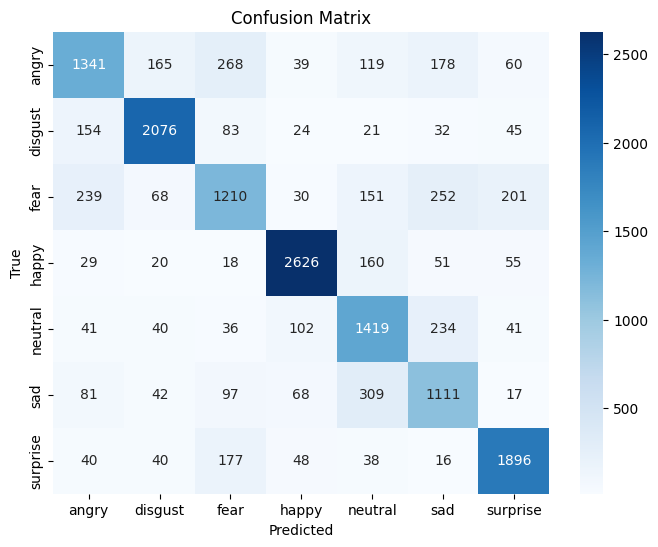

976/976 ━━━━━━━━━━━━━━━━━━━━ 116s 119ms/step
Macro-average ROC AUC: 0.9472


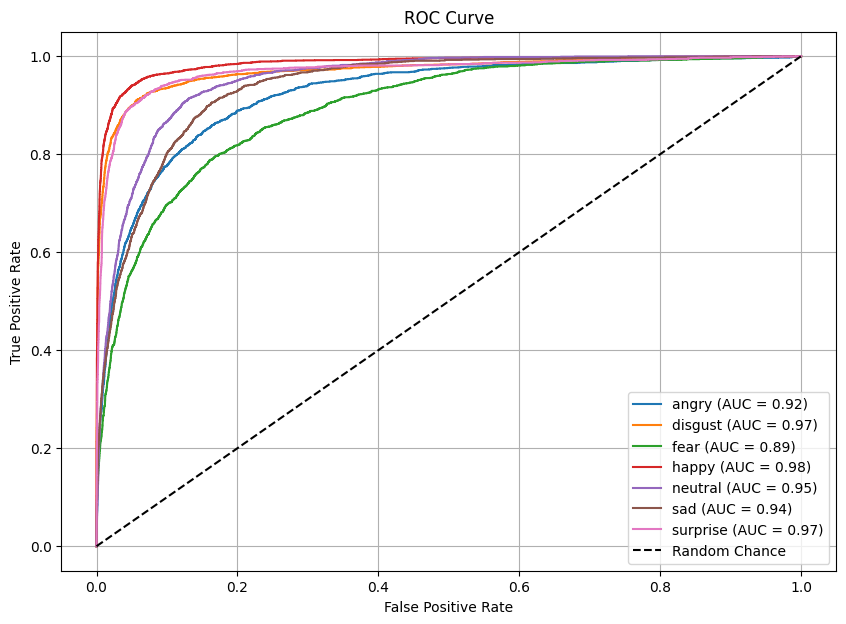


Model saved successfully to vgg16_cbam_vit_incremental_unfreeze_improved.h5

Starting Test-Time Augmentation (TTA)...
Pass 1/5: Running base prediction pass...
976/976 ━━━━━━━━━━━━━━━━━━━━ 116s 118ms/step
Found 15608 images belonging to 7 classes.
Pass 2/5: Running augmented prediction pass...
  1/976 ━━━━━━━━━━━━━━━━━━━━ 2:46 171ms/step

/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


976/976 ━━━━━━━━━━━━━━━━━━━━ 146s 149ms/step
Pass 3/5: Running augmented prediction pass...
976/976 ━━━━━━━━━━━━━━━━━━━━ 148s 151ms/step
Pass 4/5: Running augmented prediction pass...
976/976 ━━━━━━━━━━━━━━━━━━━━ 147s 150ms/step
Pass 5/5: Running augmented prediction pass...
976/976 ━━━━━━━━━━━━━━━━━━━━ 146s 149ms/step

---------------------------------------------------------
 FINAL TTA BOOSTED TEST ACCURACY: 0.7494 
---------------------------------------------------------
              precision    recall  f1-score   support

       angry       0.68      0.64      0.66      2170
     disgust       0.83      0.87      0.85      2435
        fear       0.59      0.61      0.60      2151
       happy       0.90      0.89      0.89      2959
     neutral       0.67      0.72      0.70      1913
         sad       0.64      0.56      0.60      1725
    surprise       0.82      0.85      0.83      2255

    accuracy                           0.75     15608
   macro avg       0.73      0.7

In [11]:


# =================================
# 1) Paths and Data Generators
# =================================

oversampled_train = '/kaggle/working/oversampled/train' 
preprocessed_test = '/kaggle/working/oversampled/test'

img_size = (224, 224)
batch_size = 16

# Train Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=15,       # Increased rotation range
    width_shift_range=0.1,   # Increased shift
    height_shift_range=0.1,
    brightness_range=[0.8, 1.0],  # Vary brightness
    shear_range=0.1,              # Shear transformations
    zoom_range=0.15,               # Increased zoom range
    horizontal_flip=True,
    fill_mode='reflect'
)

# Test Data Augmentation
test_datagen = ImageDataGenerator(rescale=1.0/255.0)

# Create Generators
train_generator = train_datagen.flow_from_directory(
    oversampled_train,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=True
)
test_generator = test_datagen.flow_from_directory(
    preprocessed_test,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

# =================================
# 2) Class Weight Computation
# =================================

def compute_dynamic_class_weights(generator):
    class_counts = Counter(generator.classes)
    print("Class distribution in generator:", dict(class_counts))
    classes = np.unique(generator.classes)
    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=generator.classes
    )
    return dict(enumerate(class_weights))

def visualize_class_distribution_and_weights(generator, class_weights_dict, title_prefix=""):
    class_indices = generator.class_indices
    sorted_class_names = sorted(class_indices, key=class_indices.get)

    # Gather data
    class_counts = Counter(generator.classes)
    class_sizes = []
    weights = []
    for cname in sorted_class_names:
        idx = class_indices[cname]
        class_sizes.append(class_counts[idx])
        weights.append(class_weights_dict.get(idx, 1.0))

    # Create a DataFrame for printing
    df = pd.DataFrame({
        "Class Name": sorted_class_names,
        "Number of Images": class_sizes,
        "Class Weight": weights
    })
    print(f"\n{title_prefix} Class Distribution and Weights:")
    print(df)

    # Plot Class Sizes
    plt.figure(figsize=(12, 5))
    plt.bar(sorted_class_names, class_sizes, color='skyblue')
    plt.title(f"{title_prefix} Class Sizes")
    plt.xlabel("Class")
    plt.ylabel("Number of Images")
    plt.xticks(rotation=45)
    plt.show()

    # Plot Class Weights
    plt.figure(figsize=(12, 5))
    plt.bar(sorted_class_names, weights, color='orange')
    plt.title(f"{title_prefix} Class Weights")
    plt.xlabel("Class")
    plt.ylabel("Weight")
    plt.xticks(rotation=45)
    plt.show()

class_weights_dict = compute_dynamic_class_weights(train_generator)
visualize_class_distribution_and_weights(train_generator, class_weights_dict, title_prefix="Oversampled Train")

# =================================
# 3) CBAM + VGG16 + ViT (Multi-Branch) Model Definition
# =================================

def attention_block(input_tensor):
    # Channel Attention
    avg_pool = GlobalAveragePooling2D()(input_tensor)  # (batch, channels)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=[1, 2], keepdims=False))(input_tensor)  # (batch, channels)

    reduced_channels = input_tensor.shape[-1] // 8  # Reduce dimensionality
    avg_dense = Dense(reduced_channels, activation="relu")(avg_pool)
    max_dense = Dense(reduced_channels, activation="relu")(max_pool)
    channel_attention = Dense(input_tensor.shape[-1], activation="sigmoid")(avg_dense + max_dense)
    channel_refined = Multiply()([input_tensor, Reshape((1, 1, -1))(channel_attention)])

    # Spatial Attention
    avg_pool = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(channel_refined)
    max_pool = Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(channel_refined)
    concat = Concatenate(axis=-1)([avg_pool, max_pool])
    spatial_attention = Conv2D(1, (7, 7), activation="sigmoid", padding="same")(concat)
    refined_output = Multiply()([channel_refined, spatial_attention])
    return refined_output


def build_vgg16_vit_model(num_classes):
    """
    Creates a multi-branch model that fuses features from:
      - VGG16 + CBAM CNN branch
      - Vision Transformer (ViT) branch
    Fusion is performed using an advanced Capsule Fusion Block followed by an advanced Transformer Refinement Block.
    """
    input_tensor = Input(shape=(224, 224, 3), name="image_input")

    # VGG16 + CBAM Branch
    base_model = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
    for layer in base_model.layers[:-8]:
        layer.trainable = False
    vgg_features = base_model(input_tensor)
    vgg_features = attention_block(vgg_features)
    vgg_features = GlobalAveragePooling2D()(vgg_features)
    vgg_features = Dense(256, activation="relu")(vgg_features)

    # ViT Branch
    vit_branch = ViTWrapper(pretrained_name="google/vit-base-patch16-224-in21k")
    vit_features = vit_branch(input_tensor)

    # Fuse features using the Advanced Capsule Fusion Block
    fused_capsule = AdvancedCapsuleFusionBlock(capsule_dim=256, num_iterations=2, dropout_rate=0.4)([vgg_features, vit_features])
    
    # Refine fused features with the Advanced Transformer Refinement Block
    refined_features = AdvancedTransformerRefinementBlock(num_tokens=4, token_dim=64, num_heads=4, ff_dim=128, num_layers=2, dropout_rate=0.4)(fused_capsule)
    
    # Final Classification Layer
    final_output = Dense(num_classes, activation="softmax")(refined_features)

    model = Model(inputs=input_tensor, outputs=final_output, name="Advanced_VGG16_CBAM_ViT_Model")
    return model


def incremental_unfreeze(model):
    """
    Unfreeze all layers of the model so they can be trained.
    (Mostly relevant for the VGG part in this setup.)
    """
    for layer in model.layers:
        layer.trainable = True
    model.get_layer("vit_wrapper").unfreeze_layers()  # Ensure all ViT layers are unfrozen
    return model

# =================================
# 4) Training Utilities
# =================================

def evaluate_model(model, test_generator, history):
    # Evaluate on test data
    test_loss, test_accuracy = model.evaluate(test_generator)
    print(f"\nFinal Test Loss: {test_loss:.4f}")
    print(f"Final Test Accuracy: {test_accuracy:.4f}")

    # Accuracy & Loss Plots
    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='Train Accuracy')
    plt.plot(history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

    # Confusion Matrix
    y_pred = np.argmax(model.predict(test_generator), axis=1)
    y_true = test_generator.classes
    class_labels = list(test_generator.class_indices.keys())

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_labels))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    # ROC AUC
    y_true_binarized = label_binarize(y_true, classes=range(len(class_labels)))
    y_pred_prob = model.predict(test_generator)
    roc_auc = roc_auc_score(y_true_binarized, y_pred_prob, average="macro", multi_class="ovr")
    print(f"Macro-average ROC AUC: {roc_auc:.4f}")

    # Plot ROC Curve
    plt.figure(figsize=(10, 7))
    for i in range(len(class_labels)):
        fpr, tpr, _ = roc_curve(y_true_binarized[:, i], y_pred_prob[:, i])
        per_class_auc = roc_auc_score(y_true_binarized[:, i], y_pred_prob[:, i])
        plt.plot(fpr, tpr, label=f"{class_labels[i]} (AUC = {per_class_auc:.2f})")
    plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
    plt.title('ROC Curve')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()
    plt.grid()
    plt.show()

# Normalize class weights for Focal Loss
alpha = np.array(list(class_weights_dict.values()))
alpha /= np.sum(alpha)

import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Define the modular loss function factory
def get_optimized_loss(alpha_weights, gamma_value=2.0):
    """
    Returns a compiled Focal Loss function.
    Setting gamma >= 2.0 aggressively suppresses gradients from easy majority classes (like Happy/Neutral).
    """
    return focal_loss(alpha=alpha_weights, gamma=gamma_value)

# 2. Updated TTA Function to accept an in-memory model directly
def evaluate_with_tta(model, test_generator, tta_steps=5):
    print("\n==========================================")
    print("Starting Test-Time Augmentation (TTA)...")
    print("==========================================")
    
    # If a file path string is passed instead of a model object, load it safely
    if isinstance(model, str):
        print(f"Loading model from disk: {model}")
        model = tf.keras.models.load_model(
            model, 
            compile=False,
            custom_objects={
                "ViTWrapper": ViTWrapper,
                "AdvancedCapsuleFusionBlock": AdvancedCapsuleFusionBlock,
                "AdvancedTransformerRefinementBlock": AdvancedTransformerRefinementBlock,
                "PositionalEmbedding": PositionalEmbedding,
                "TransformerEncoderBlock": TransformerEncoderBlock
            }
        )
    
    # Reset generator to start from the first batch
    test_generator.reset()
    y_true = test_generator.classes
    num_samples = len(y_true)
    num_classes = len(test_generator.class_indices)
    
    # Accumulate probability predictions across passes
    tta_predictions = np.zeros((num_samples, num_classes))
    
    # Step 1: Base unaugmented predictions
    print("Pass 1/5: Running base prediction pass...")
    test_generator.reset()
    tta_predictions += model.predict(test_generator, verbose=1)
    
    # Step 2: Configure light TTA transformations (flips and tiny zooms)
    tta_datagen = ImageDataGenerator(
        rescale=1.0/255.0,
        horizontal_flip=True,
        zoom_range=0.08
    )
    
    tta_generator = tta_datagen.flow_from_directory(
        test_generator.directory,
        target_size=test_generator.target_size,
        batch_size=test_generator.batch_size,
        class_mode="categorical",
        shuffle=False
    )
    
    # Step 3: Run augmented passes
    for step in range(1, tta_steps):
        print(f"Pass {step + 1}/{tta_steps}: Running augmented prediction pass...")
        tta_generator.reset()
        tta_predictions += model.predict(tta_generator, verbose=1)
        
    # Average the softmax probabilities across all passes
    tta_predictions /= tta_steps
    final_preds = np.argmax(tta_predictions, axis=1)
    
    acc = accuracy_score(y_true, final_preds)
    print("\n---------------------------------------------------------")
    print(f" FINAL TTA BOOSTED TEST ACCURACY: {acc:.4f} ")
    print("---------------------------------------------------------")
    print(classification_report(y_true, final_preds, target_names=list(test_generator.class_indices.keys())))
    return acc

def train_model():
    # ============= Build & Compile the Multi-Branch Model =============
    num_classes = train_generator.num_classes
    model = build_vgg16_vit_model(num_classes)
    loss_fn = get_optimized_loss(alpha_weights=alpha, gamma_value=2.0)

    model.compile(
        optimizer=AdamW(learning_rate=3e-5, weight_decay=1e-3),
        loss=loss_fn,
        metrics=["accuracy"]
    )

    early_stopping = EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
    mixup_train_sequence = MixupSequence(train_generator, alpha=0.1)
    
    print("\n=== Phase 1 Training ===")
    history_phase1 = model.fit(
        mixup_train_sequence,
        validation_data=test_generator,
        epochs=25,
        callbacks=[early_stopping, reduce_lr]
    )

    # Incremental unfreeze
    for layer in model.layers:
        layer.trainable = True  # Now unfreeze everything
    model.get_layer("vi_t_wrapper").unfreeze_layers()

    model.compile(
        optimizer=AdamW(learning_rate=1e-5, weight_decay=1e-3),
        loss=loss_fn,
        metrics=["accuracy"]
    )
    print("\n=== Phase 2 Fine-tuning ===")
    history_phase2 = model.fit(
        mixup_train_sequence,
        validation_data=test_generator,
        epochs=35,
        callbacks=[early_stopping, reduce_lr]
    )

    # Combine Phase 1 & 2 histories
    history = {
        'accuracy': history_phase1.history['accuracy'] + history_phase2.history['accuracy'],
        'val_accuracy': history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy'],
        'loss': history_phase1.history['loss'] + history_phase2.history['loss'],
        'val_loss': history_phase1.history['val_loss'] + history_phase2.history['val_loss']
    }

    # Standard Evaluation
    evaluate_model(model, test_generator, history)
    
    # Save Final Weights
    save_path = "vgg16_cbam_vit_incremental_unfreeze_improved.h5"
    model.save(save_path)
    print(f"\nModel saved successfully to {save_path}")
    
    return model

# =================================
# 5) Run Training & TTA Pipeline
# =================================

if __name__ == "__main__":
    # 1. Train and perform standard evaluation
    final_model = train_model()
    
    # 2. Immediately execute Test-Time Augmentation on the in-memory model
    evaluate_with_tta(final_model, test_generator, tta_steps=5)

# cross validate

In [12]:
import os
import shutil
import cv2
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Apply CLAHE to improve contrast
def preprocess_image(image_path, target_size=(224, 224)):
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    image = cv2.resize(image, target_size)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(image)

# Preprocess and save images to a new directory
def preprocess_dataset(input_dir, output_dir, target_size=(224, 224)):
    os.makedirs(output_dir, exist_ok=True)
    for emotion in os.listdir(input_dir):
        emotion_dir = os.path.join(input_dir, emotion)
        output_emotion_dir = os.path.join(output_dir, emotion)
        os.makedirs(output_emotion_dir, exist_ok=True)

        for img_name in os.listdir(emotion_dir):
            img_path = os.path.join(emotion_dir, img_name)
            processed_img = preprocess_image(img_path, target_size=target_size)
            output_path = os.path.join(output_emotion_dir, img_name)
            cv2.imwrite(output_path, processed_img)

# Preprocess testing datasets
cross_test = '/kaggle/working/cross/test'

combined_test = '/kaggle/input/emotion-detection-fer/test'

preprocess_dataset(combined_test, cross_test)
print("Preprocessing completed!")

Preprocessing completed!


Found 7178 images belonging to 7 classes.
  1/449 ━━━━━━━━━━━━━━━━━━━━ 1:21 183ms/step - accuracy: 0.3750 - loss: 0.1418

/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


449/449 ━━━━━━━━━━━━━━━━━━━━ 62s 139ms/step - accuracy: 0.6346 - loss: 0.0951

emotion-detection-fer - Test Loss: 0.0768
emotion-detection-fer - Test Accuracy: 0.6875
449/449 ━━━━━━━━━━━━━━━━━━━━ 56s 126ms/step

emotion-detection-fer - Classification Report:
              precision    recall  f1-score   support

       angry       0.67      0.57      0.62       958
   disgusted       0.64      0.77      0.70       111
     fearful       0.59      0.46      0.52      1024
       happy       0.89      0.88      0.88      1774
     neutral       0.58      0.72      0.64      1233
         sad       0.55      0.56      0.56      1247
   surprised       0.78      0.83      0.80       831

    accuracy                           0.69      7178
   macro avg       0.67      0.68      0.67      7178
weighted avg       0.69      0.69      0.69      7178



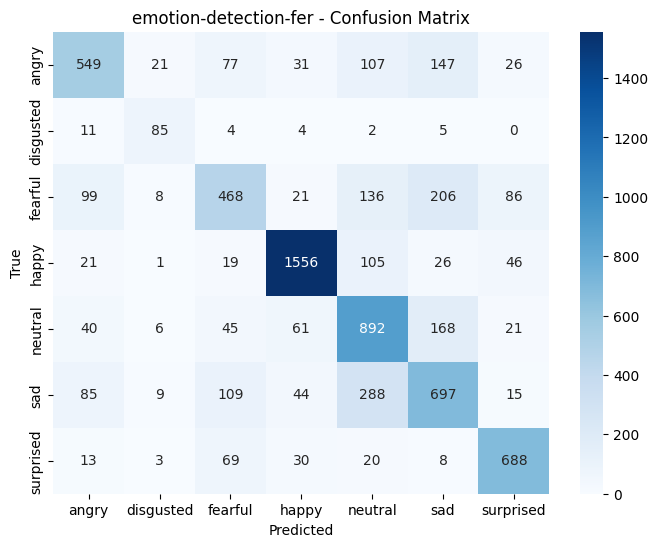

In [13]:
# Cross-Validation on a New Dataset (FERPlus as an example)
new_dataset_path =  '/kaggle/working/cross/test' 

# Create Test Generator
new_test_generator = test_datagen.flow_from_directory(
    new_dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

# Evaluate on the New Dataset
def evaluate_on_new_dataset(model, test_generator, dataset_name="New Dataset"):
    """
    Evaluate the trained model on another dataset.
    """
    test_loss, test_accuracy = model.evaluate(test_generator)
    print(f"\n{dataset_name} - Test Loss: {test_loss:.4f}")
    print(f"{dataset_name} - Test Accuracy: {test_accuracy:.4f}")

    # Classification Report
    y_pred = np.argmax(model.predict(test_generator), axis=1)
    y_true = test_generator.classes
    class_labels = list(test_generator.class_indices.keys())

    print(f"\n{dataset_name} - Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_labels))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f"{dataset_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

# Evaluate on FERPlus (or any other dataset)
evaluate_on_new_dataset(final_model, new_test_generator, dataset_name="emotion-detection-fer")
